# 05 — Correlations, per clean acquisition run

Same analysis as `05_correlations.ipynb`, done separately for every run listed in `CLEAN_CUTS.toml`
(only the clean chunks). The stitched acquisition follows later, after normalisation.

Differences to notebook 05:
- **data**: `DATA_ROOT/acquisition_*/h5/chunk_*.h5`, chunk selection from `CLEAN_CUTS.toml`
- **camera**: the classic BTV0125 parameters (notebook 04) are computed here per run and cached as CSV;
  the PCA scores (notebook 04_1) are not included
- **segments**: removed chunks leave gaps inside a run. The group-B shift and the 51-shot detrending are done per
  contiguous segment, so no shot is paired with a shot on the other side of a gap
- **lag**: group B is shifted by a fixed +1 row as in 05; the lag scan per run shows whether this holds

Results are shown per run and saved to `OUT_ROOT/<run>/`. The last section compares the runs.

In [11]:
import os
import tomllib
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import ndimage

DATA_ROOT = Path("/data/optimisation/measured_data")  # folder with the acquisition_* runs
CUTS_FILE = Path("../config/CLEAN_CUTS.toml")          # relative to the notebook's working directory
OUT_ROOT = Path.cwd().parent / "results" / "05_correlations"
N_WORKERS = min(8, os.cpu_count())                        # camera processing; each worker holds one chunk (~0.5 GB)

# diverging blue <-> red with a neutral grey midpoint (r = 0)
DIVERGING = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#cde2fb", "#f0efec", "#f6c6c5", "#e34948", "#9b1c1c"])
INK, MUTED, POINT = "#2b2b29", "#8a8985", "#2a78d6"

## Clean chunks per run (`CLEAN_CUTS.toml`)

In [12]:
def expand(keep):
    # [[0, 10], 12, [15, 20]] -> chunk numbers; a pair is an inclusive range, a single int one chunk
    out = []
    for item in keep:
        if isinstance(item, int):
            out.append(item)
        else:
            a, b = item
            out.extend(range(a, b + 1))
    return out


def clean_chunks(cuts_file=CUTS_FILE, root=DATA_ROOT):
    # {run: [chunk paths to use]}; warns about listed chunks that do not exist
    with open(cuts_file, "rb") as f:
        cuts = tomllib.load(f)
    out = {}
    for run, spec in cuts.items():
        files = {int(p.stem[6:]): p for p in sorted((root / run / "h5").glob("chunk_*.h5"))}
        wanted = sorted(files) if spec["keep"] == "all" else expand(spec["keep"])
        absent = [i for i in wanted if i not in files]
        if absent:
            print(f"{run}: listed but not found: chunks {absent}")
        out[run] = [files[i] for i in wanted if i in files]
    return out


clean = clean_chunks()
RUNS = sorted(clean)
for i, run in enumerate(RUNS):
    print(f"[{i}] {run}: {len(clean[run])} clean chunks")

[0] acquisition_2026-10-07_21-43-26: 61 clean chunks
[1] acquisition_2026-10-08_00-08-19: 194 clean chunks
[2] acquisition_2026-10-08_15-42-27: 118 clean chunks
[3] acquisition_2026-10-08_21-11-47: 200 clean chunks
[4] acquisition_2026-10-09_07-46-07: 61 clean chunks


## Helpers

- `load(files, key)` concatenates one variable over the chunks
- `shot_index(files)` gives the chunk number of every shot and the contiguous segment it belongs to

In [13]:
def load(files, key):
    out = []
    for path in files:
        with h5py.File(path, "r") as f:
            out.append(f[key][:])
    return np.concatenate(out)


def shot_index(files):
    # per shot: chunk number, and segment id (a new segment starts wherever chunks were removed)
    chunk = []
    for path in files:
        with h5py.File(path, "r") as f:
            chunk += [int(path.stem[6:])] * int(f.attrs["n_shots"])
    chunk = np.array(chunk)
    segment = np.r_[0, np.cumsum(~np.isin(np.diff(chunk), (0, 1)))]
    return chunk, segment


def shift_in_segment(df, segment, lag):
    # row i <- row i + lag of the same segment (NaN where that row is in another segment)
    return df.groupby(segment).shift(-lag)


def detrend(df, segment, k=51):
    # remove slow drift: subtract a k-shot centred rolling mean, per segment
    trend = df.groupby(segment).transform(lambda s: s.rolling(k, center=True, min_periods=1).mean())
    return df - trend


def save(fig, path):
    fig.savefig(path, dpi=130, bbox_inches="tight")

## Camera: classic BTV0125 parameters (from notebook 04)

ROI crop, background from the top rows, 3×3 median filter, peak of a σ = 3 px Gaussian-smoothed copy,
mask = largest blob above 5 % of the peak, moments inside the mask (mm).
`frozen` = the camera repeated its previous image (same `imageNumber`).
Computed once per run with `N_WORKERS` processes and cached in `OUT_ROOT/<run>/btv0125_params.csv`.

In [14]:
ROI = (slice(350, 1150), slice(600, 1450))  # rows, cols — beam moves within rows ~640–830, cols ~930–1160
BG_ROWS = slice(0, 150)                     # top rows of the full image, no beam there
THRESHOLD = 0.05                            # keep pixels above 5% of the peak
BTV_COLS = ["amplitude", "intensity", "mean_x", "mean_y", "sigma_x", "sigma_y"]


def first_non_empty(obj):
    arrays = [obj[k][:] for k in sorted(obj)] if isinstance(obj, h5py.Group) else obj[:]
    return next(a for a in arrays if a.size)


def clean_image(raw):
    raw = raw.astype(np.float32)
    background = np.median(raw[BG_ROWS])
    return ndimage.median_filter(raw[ROI], size=3) - background


def beam_params(raw, x_mm, y_mm):
    img = clean_image(raw)
    smooth = ndimage.gaussian_filter(img, 3)
    peak = smooth.max()
    labels, n_blobs = ndimage.label(smooth > THRESHOLD * peak)
    if peak <= 0 or n_blobs == 0:                    # blank image: no beam, or the camera sent zeros
        return dict.fromkeys(BTV_COLS, np.nan)
    img = img *(labels == np.bincount(labels.ravel())[1:].argmax() + 1)
    total = img.sum()
    proj_x, proj_y = img.sum(axis=0), img.sum(axis=1)
    mean_x = proj_x @ x_mm / total
    mean_y = proj_y @ y_mm / total
    return {"amplitude": peak, "intensity": total, "mean_x": mean_x, "mean_y": mean_y,
            "sigma_x": np.sqrt(proj_x @ (x_mm - mean_x) ** 2 / total),
            "sigma_y": np.sqrt(proj_y @ (y_mm - mean_y) ** 2 / total)}


def btv_chunk(path):
    # all shots of one chunk -> list of row dicts (runs in a worker process)
    with h5py.File(path, "r") as f:
        btv = f["BTV0125"]
        x_mm = first_non_empty(btv["imagePositionSet1"])[ROI[1]]
        y_mm = first_non_empty(btv["imagePositionSet2"])[ROI[0]]
        images = btv["image2D"][:]
        numbers = btv["imageNumber"][:]
    return [{"chunk": path.stem, "image_number": numbers[i], **beam_params(images[i], x_mm, y_mm)}
            for i in range(len(numbers))]


def btv_params(run, files):
    cache = OUT_ROOT / run / "btv0125_params.csv"
    if cache.exists():
        df = pd.read_csv(cache, index_col="shot")
        if df["chunk"].unique().tolist() == [p.stem for p in files]:   # same chunks, same order
            print(f"camera: cached {cache}")
            return df
        print("camera: cache does not match the clean chunks, recomputing")
    cache.parent.mkdir(parents=True, exist_ok=True)
    with ProcessPoolExecutor(N_WORKERS, mp_context=mp.get_context("fork")) as pool:
        rows = [r for chunk_rows in pool.map(btv_chunk, files) for r in chunk_rows]
    df = pd.DataFrame(rows)
    df["frozen"] = df["image_number"].diff().eq(0)  # camera repeated its previous image
    df.to_csv(cache, index_label="shot")
    print(f"camera: computed {len(df)} shots, {df['amplitude'].isna().sum()} blank images (NaN) -> {cache}")
    return df

## Per-run analysis

`analyse_run(run)` does what notebook 05 does, on the clean chunks of one run:
1. per-shot table (as recorded): charge, laser matched filter (template = mean pulse of this run), lab laser power,
   RF features, magnets, camera
2. lag scan of every quantity against `BCM_GUN` (lags −2…+2, per segment)
3. align (group B one row later) and drop frozen laser-scope / camera shots
4. correlation matrices, overall and shot-to-shot (drift removed)
5. strongest shot-to-shot pairs (camera–camera pairs excluded) and their scatter plots

In [15]:
FLAT_TOP = slice(300, 640)
GROUP_B = ["laser_amp", "lab_laser_power", "PGLA_drop", "PKI15A", "PKI15P", "PKR15A"]
GROUP_EDGES = ["laser_amp", "PGLA_drop", "DHG0130", "BTV_amplitude"]  # first column of each group after charge
LAGS = np.arange(-2, 3)


def build_table(run, files):
    signal = load(files, "laser_scope/signal")
    with h5py.File(files[0], "r") as f:
        t = f["laser_scope/times"][0]
    clean_sig = signal - signal[:, t < 5].mean(axis=1, keepdims=True)
    template = clean_sig.mean(axis=0) * ((t > 5.6) & (t < 39.8))   # mean pulse of this run
    laser_frozen = np.r_[False, np.all(signal[1:] == signal[:-1], axis=1)]

    pgla = load(files, "PGLA/samples")[:, 0]
    raw = pd.DataFrame({
        "BCM_GUN": load(files, "BCM_GUN"),
        "laser_amp": clean_sig @ template / (template @ template),
        "lab_laser_power": load(files, "lab_laser_power"),
        "PGLA_drop": pgla[:, 631] - pgla[:, 636],
        "PKI15A": load(files, "PKI15A/samples")[:, 0, FLAT_TOP].mean(axis=1),
        "PKI15P": load(files, "PKI15P")[:, 0, FLAT_TOP].mean(axis=1),
        "PKR15A": load(files, "PKR15A")[:, 0, FLAT_TOP].mean(axis=1),
        "DHG0130": load(files, "DHG0130"),
        "SNH_110": load(files, "SNH_110"),
        "SNI_120": load(files, "SNI_120"),
    })
    btv = btv_params(run, files)
    for c in BTV_COLS:
        raw[f"BTV_{c}"] = btv[c].to_numpy()
    return raw, laser_frozen, btv["frozen"].to_numpy()


def plot_lag_scan(raw, segment, run, out):
    bcm_d = detrend(raw[["BCM_GUN"]], segment)["BCM_GUN"]
    x_d = detrend(raw.drop(columns="BCM_GUN"), segment)
    lag_table = pd.DataFrame({lag: shift_in_segment(x_d, segment, lag).corrwith(bcm_d) for lag in LAGS})

    fig, ax = plt.subplots(figsize=(6, 0.36 * len(lag_table) + 1.5))
    im = ax.imshow(lag_table, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
    for (i, j), r in np.ndenumerate(lag_table.to_numpy()):
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(r) > 0.6 else INK)
    ax.set_xticks(range(len(LAGS)), [f"{lag:+d}" for lag in LAGS])
    ax.set_yticks(range(len(lag_table)), lag_table.index)
    ax.set(xlabel="lag (rows)", title=f"{run}\nShot-to-shot r: X[i + lag] vs BCM_GUN[i]")
    fig.colorbar(im, ax=ax, shrink=0.6, label="r")
    fig.tight_layout()
    save(fig, out / "lag_scan.png")
    plt.show()
    return lag_table


def align_and_clean(raw, segment, laser_frozen, btv_frozen):
    data = raw.copy()
    data[GROUP_B] = shift_in_segment(raw[GROUP_B], segment, 1)    # row i now holds group B from row i + 1
    laser_frozen_aligned = shift_in_segment(pd.DataFrame({"f": laser_frozen}), segment, 1)["f"].eq(True).to_numpy()
    complete = data[GROUP_B].notna().all(axis=1).to_numpy()      # last row of each segment has no partner
    keep = ~laser_frozen_aligned & ~btv_frozen & complete
    print(f"kept {keep.sum()} / {len(keep)} shots (dropped {laser_frozen_aligned.sum()} frozen laser, "
          f"{btv_frozen.sum()} frozen camera, {(~complete).sum()} lost to the shift)")
    return data[keep], segment[keep]


def plot_matrices(data, segment, run, out):
    matrices = {"Overall": data.corr(), "Shot-to-shot (drift removed)": detrend(data, segment).corr()}
    names = data.columns
    lower = np.tril(np.ones((len(names), len(names)), dtype=bool), k=-1)
    edges = [names.get_loc(c) - 0.5 for c in GROUP_EDGES]
    for (title, m), fname in zip(matrices.items(), ["corr_overall.png", "corr_shot_to_shot.png"]):
        fig, ax = plt.subplots(figsize=(12, 10))
        shown = np.where(lower, m.to_numpy(), np.nan)
        im = ax.imshow(shown, cmap=DIVERGING, vmin=-1, vmax=1)
        for (i, j), r in np.ndenumerate(shown):
            if not np.isnan(r):
                ax.text(j, i, f"{r:.2f}".replace("0.", "."), ha="center", va="center", fontsize=7,
                        color="white" if abs(r) > 0.6 else (INK if abs(r) >= 0.1 else MUTED))
        for e in edges:
            ax.axhline(e, color=MUTED, lw=0.6)
            ax.axvline(e, color=MUTED, lw=0.6)
        ax.set_xticks(range(len(names)), names, rotation=60, ha="right", fontsize=8)
        ax.set_yticks(range(len(names)), names, fontsize=8)
        ax.set_title(f"{run} — {title}  ({len(data)} shots)")
        for spine in ax.spines.values():
            spine.set_visible(False)
        fig.colorbar(im, ax=ax, shrink=0.6, label="Pearson r")
        fig.tight_layout()
        save(fig, out / fname)
        plt.show()
    return matrices, lower


def top_pairs(matrices, lower, data, run, out, n_table=12, n_plot=6):
    m = matrices["Shot-to-shot (drift removed)"]
    camera = [c for c in data.columns if c.startswith("BTV_")]
    pairs = (m.where(lower).stack().rename("r").reset_index()
             .assign(abs_r=lambda d: d["r"].abs()).sort_values("abs_r", ascending=False))
    pairs = pairs[~(pairs["level_0"].isin(camera) & pairs["level_1"].isin(camera))].drop(columns="abs_r")
    pairs.to_csv(out / "top_pairs.csv", index=False)

    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, (_, row) in zip(axes.ravel(), pairs.head(n_plot).iterrows()):
        x, y = row["level_1"], row["level_0"]
        ax.scatter(data[x], data[y], s=8, color=POINT, alpha=0.35, edgecolors="none")
        r_all = matrices["Overall"].loc[y, x]
        ax.set(xlabel=x, ylabel=y, title=f"shot-to-shot r = {row['r']:.2f}   |   overall r = {r_all:.2f}")
        ax.title.set_fontsize(10)
        ax.grid(color="#e6e5e1", lw=0.6)
        ax.set_axisbelow(True)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
    fig.suptitle(run)
    fig.tight_layout()
    save(fig, out / "top_pairs.png")
    plt.show()
    return pairs.head(n_table).round(2)


def analyse_run(run):
    files = clean[run]
    out = OUT_ROOT / run
    out.mkdir(parents=True, exist_ok=True)
    chunk, segment = shot_index(files)
    print(f"{run}: {len(files)} chunks, {len(chunk)} shots, {segment.max() + 1} contiguous segment(s)")

    raw, laser_frozen, btv_frozen = build_table(run, files)
    display(raw.describe().T[["mean", "std", "min", "max"]])
    lag_table = plot_lag_scan(raw, segment, run, out)
    data, seg_kept = align_and_clean(raw, segment, laser_frozen, btv_frozen)
    matrices, lower = plot_matrices(data, seg_kept, run, out)
    display(top_pairs(matrices, lower, data, run, out))
    return {"n_shots": len(raw), "n_kept": len(data), "lag_table": lag_table, "matrices": matrices}


results = {}

## Run 0

acquisition_2026-10-07_21-43-26: 61 chunks, 6027 shots, 1 contiguous segment(s)
camera: computed 6027 shots, 74 blank images (NaN) -> /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/05_correlations/acquisition_2026-10-07_21-43-26/btv0125_params.csv


,mean,std,min,max
BCM_GUN,0.223371,2.666711e-02,0.146083,3.735706e-01
laser_amp,1.000000,9.376533e-02,0.610755,1.356453e+00
lab_laser_power,0.000004,6.595929e-08,0.000004,4.098661e-06
PGLA_drop,0.539078,1.057513e+00,-2.929688,3.906250e+00
PKI15A,131.645449,1.850672e-01,131.155216,1.325454e+02
PKI15P,-24.967787,1.168159e-01,-25.310202,-2.453182e+01
PKR15A,-5.900759,9.868201e-02,-6.215533,-5.531939e+00
DHG0130,1.500619,1.300984e-03,1.496581,1.504598e+00
SNH_110,220.004866,7.473106e-03,219.983994,2.200310e+02
SNI_120,330.345254,1.718275e-01,329.447296,3.306986e+02


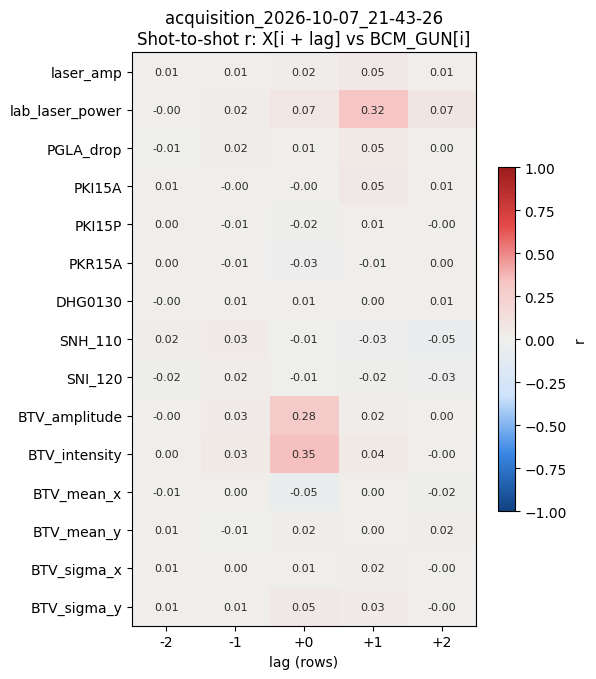

kept 4637 / 6027 shots (dropped 1386 frozen laser, 3 frozen camera, 1 lost to the shift)


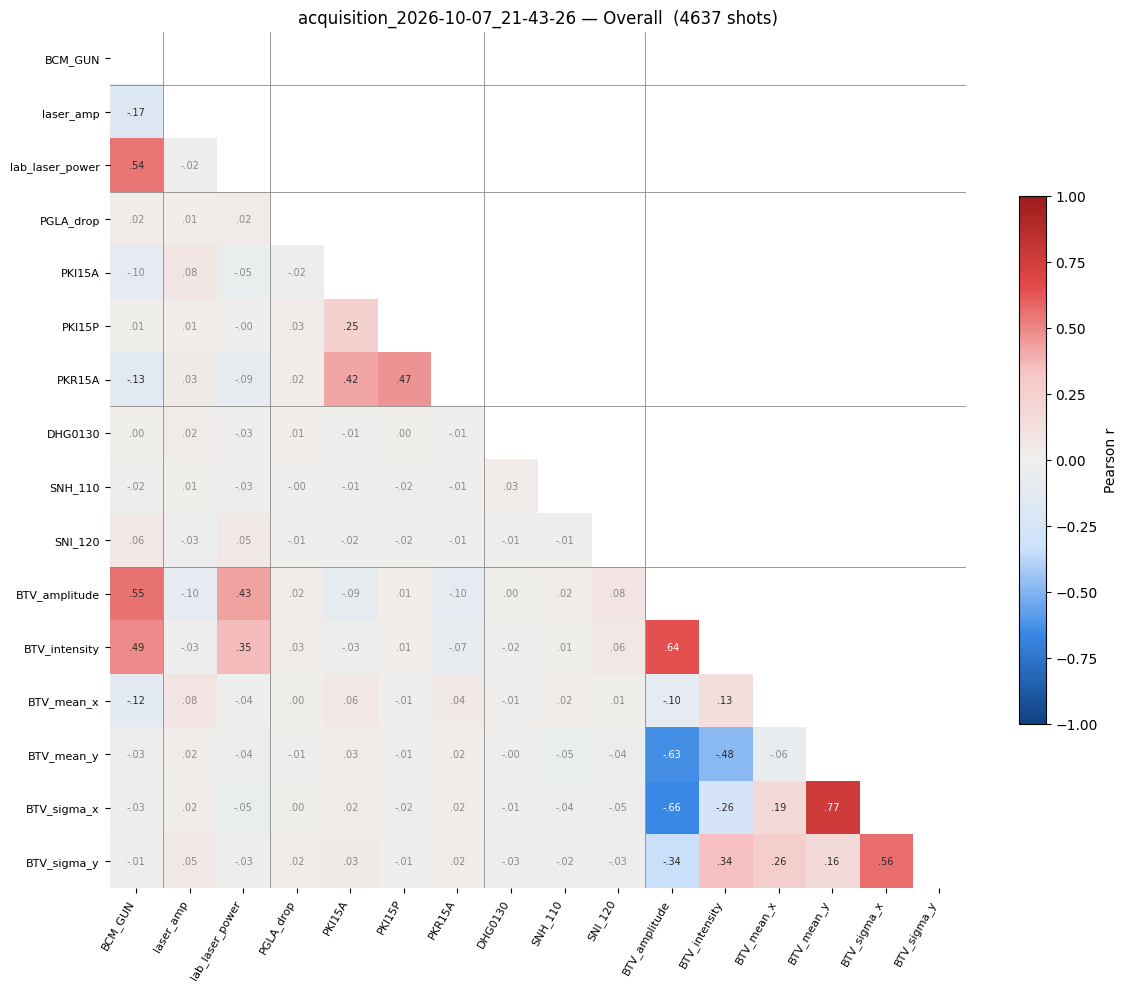

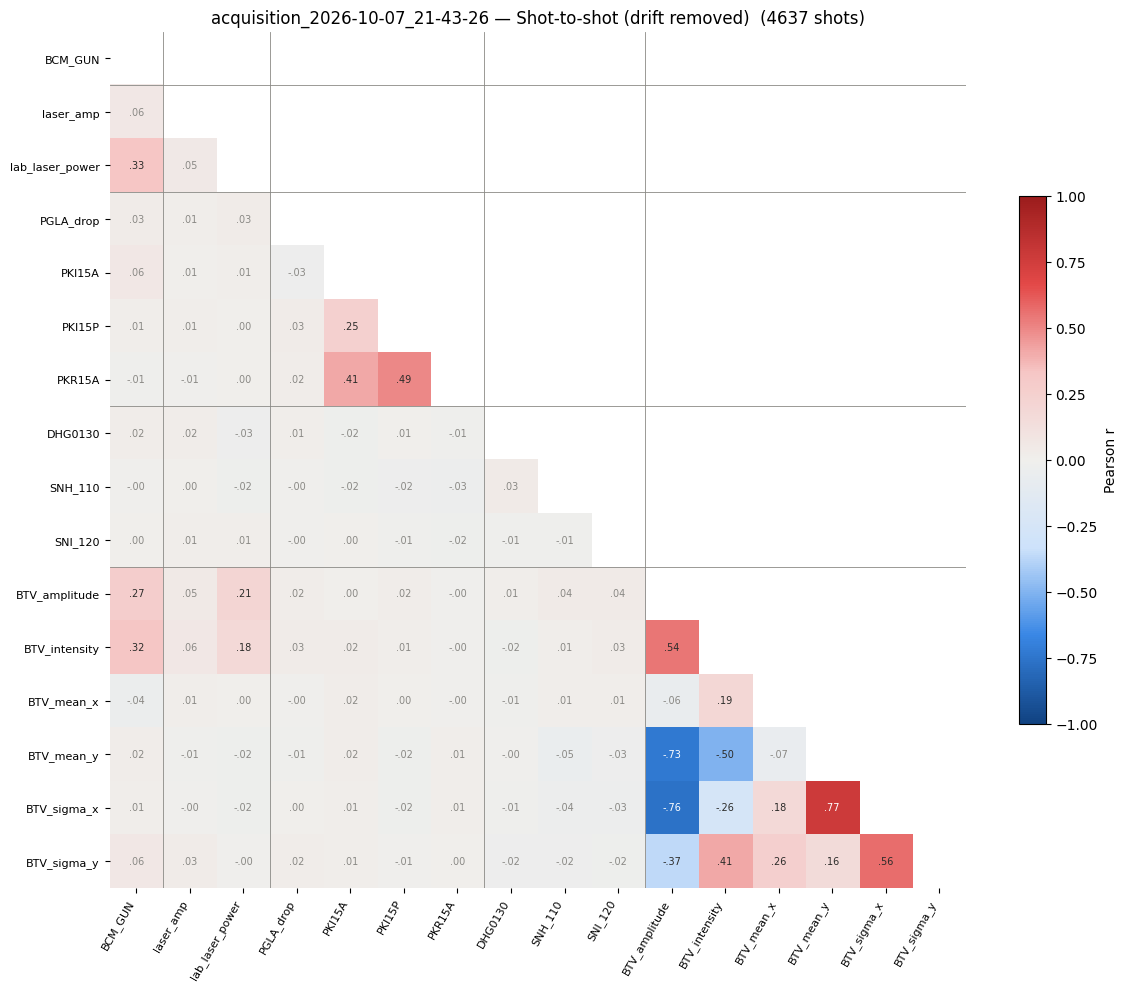

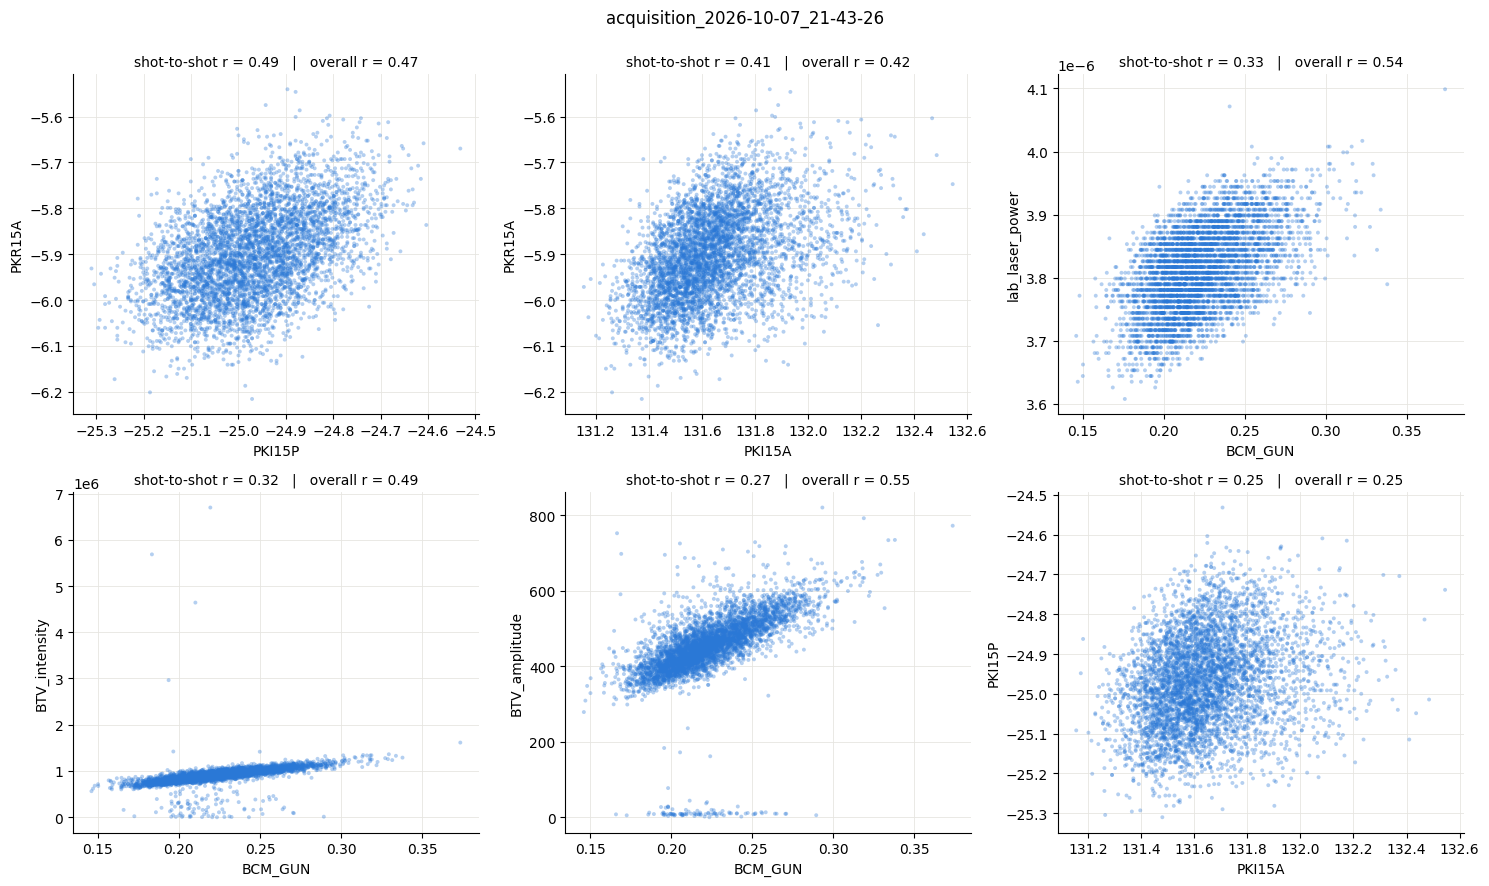

,level_0,level_1,r
20,PKR15A,PKI15P,0.49
19,PKR15A,PKI15A,0.41
1,lab_laser_power,BCM_GUN,0.33
55,BTV_intensity,BCM_GUN,0.32
45,BTV_amplitude,BCM_GUN,0.27
14,PKI15P,PKI15A,0.25
47,BTV_amplitude,lab_laser_power,0.21
57,BTV_intensity,lab_laser_power,0.18
105,BTV_sigma_y,BCM_GUN,0.06
0,laser_amp,BCM_GUN,0.06


In [16]:
results[RUNS[0]] = analyse_run(RUNS[0])

## Run 1

acquisition_2026-10-08_00-08-19: 194 chunks, 19400 shots, 1 contiguous segment(s)


/tmp/ipykernel_1489128/2563599605.py:31: RuntimeWarning: invalid value encountered in sqrt
  "sigma_x": np.sqrt(proj_x @ (x_mm - mean_x) ** 2 / total),


camera: computed 19400 shots, 264 blank images (NaN) -> /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/05_correlations/acquisition_2026-10-08_00-08-19/btv0125_params.csv


,mean,std,min,max
BCM_GUN,4.828807e+00,4.177860e-01,-3.796276,6.530779e+00
laser_amp,1.000000e+00,1.431782e-01,0.513217,1.589675e+00
lab_laser_power,1.008499e-05,4.770446e-07,0.000008,1.212330e-05
PGLA_drop,6.038479e+00,1.196265e+00,-23.437500,1.074219e+01
PKI15A,1.317485e+02,1.191221e+00,7.301241,1.326545e+02
PKI15P,-2.500364e+01,1.190342e-01,-25.416475,-2.456629e+01
PKR15A,-5.926630e+00,1.005364e-01,-6.298828,-5.537684e+00
DHG0130,1.500593e+00,1.290156e-03,1.495436,1.504980e+00
SNH_110,2.200048e+02,7.595586e-03,219.983994,2.200260e+02
SNI_120,3.303385e+02,1.666167e-01,329.447296,3.306986e+02


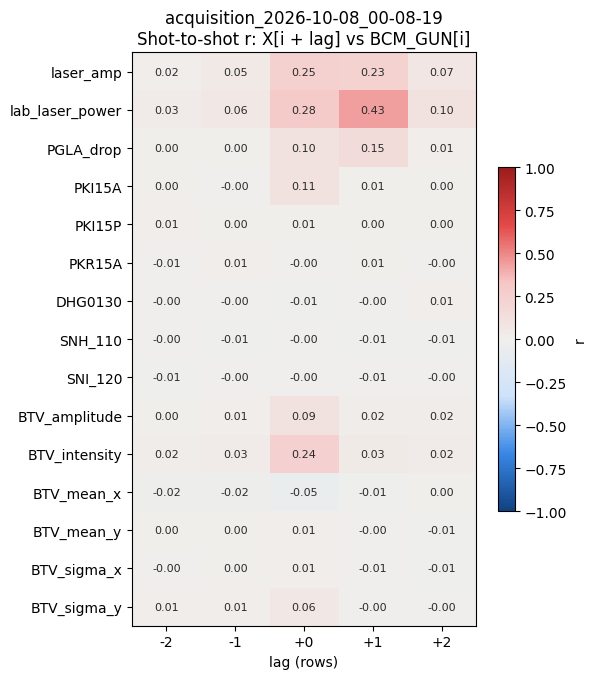

kept 16658 / 19400 shots (dropped 2642 frozen laser, 116 frozen camera, 1 lost to the shift)


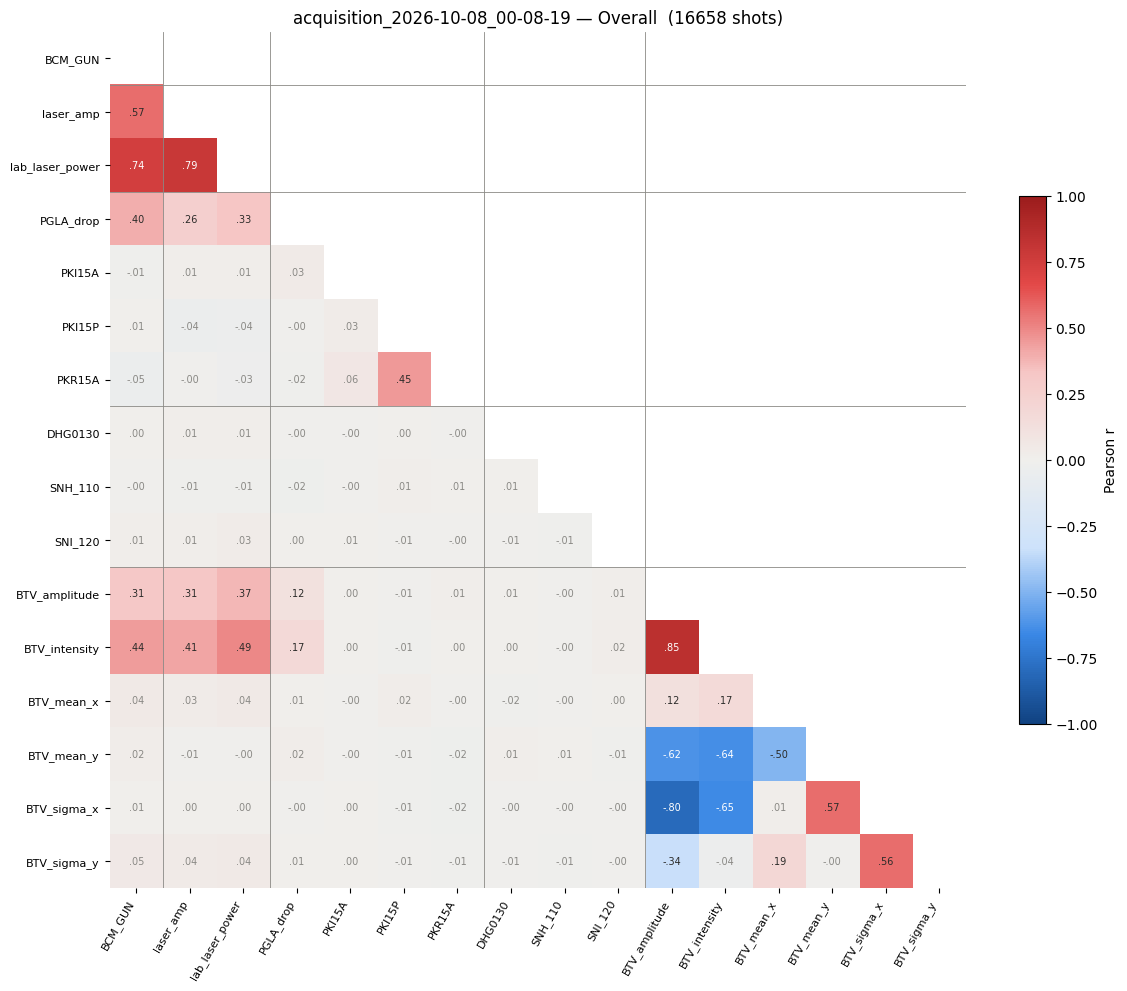

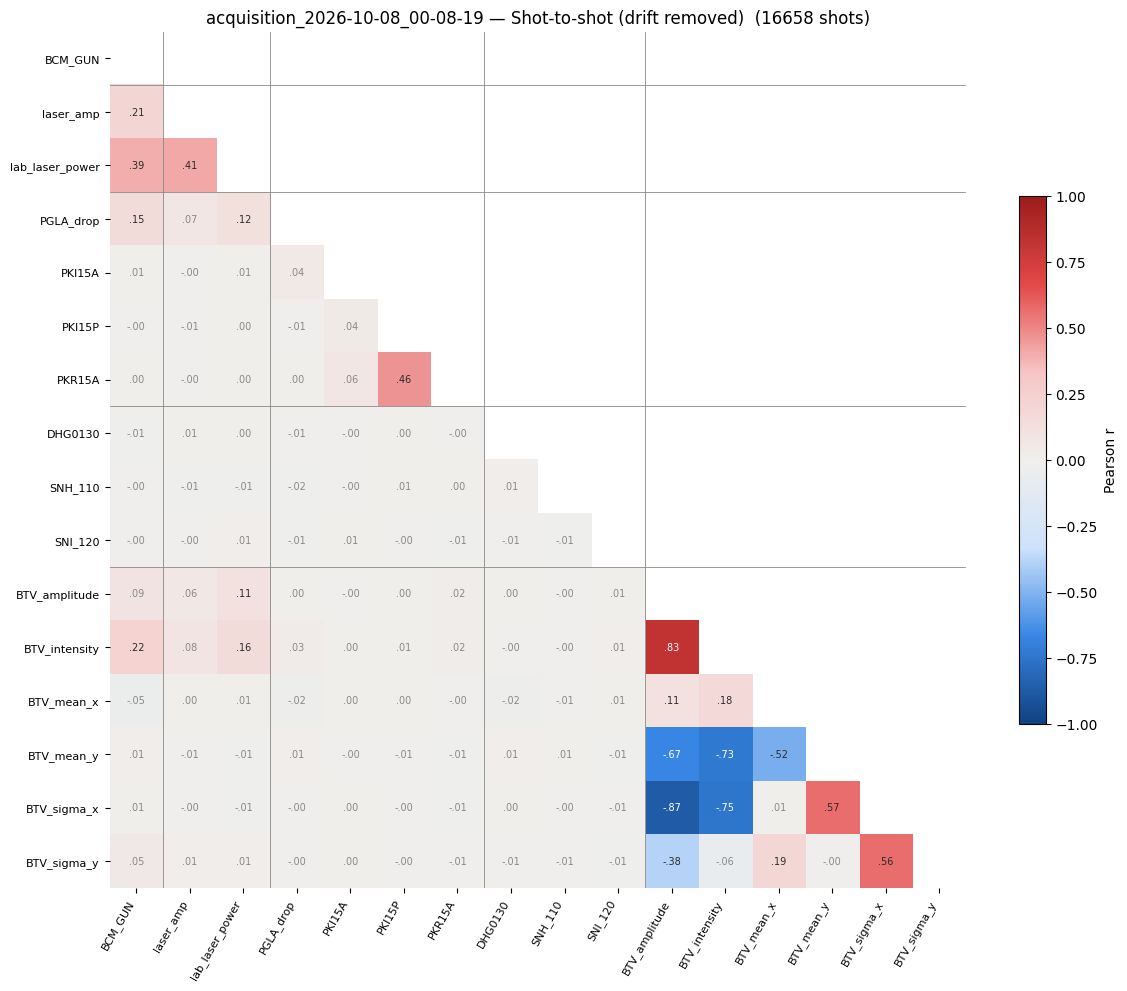

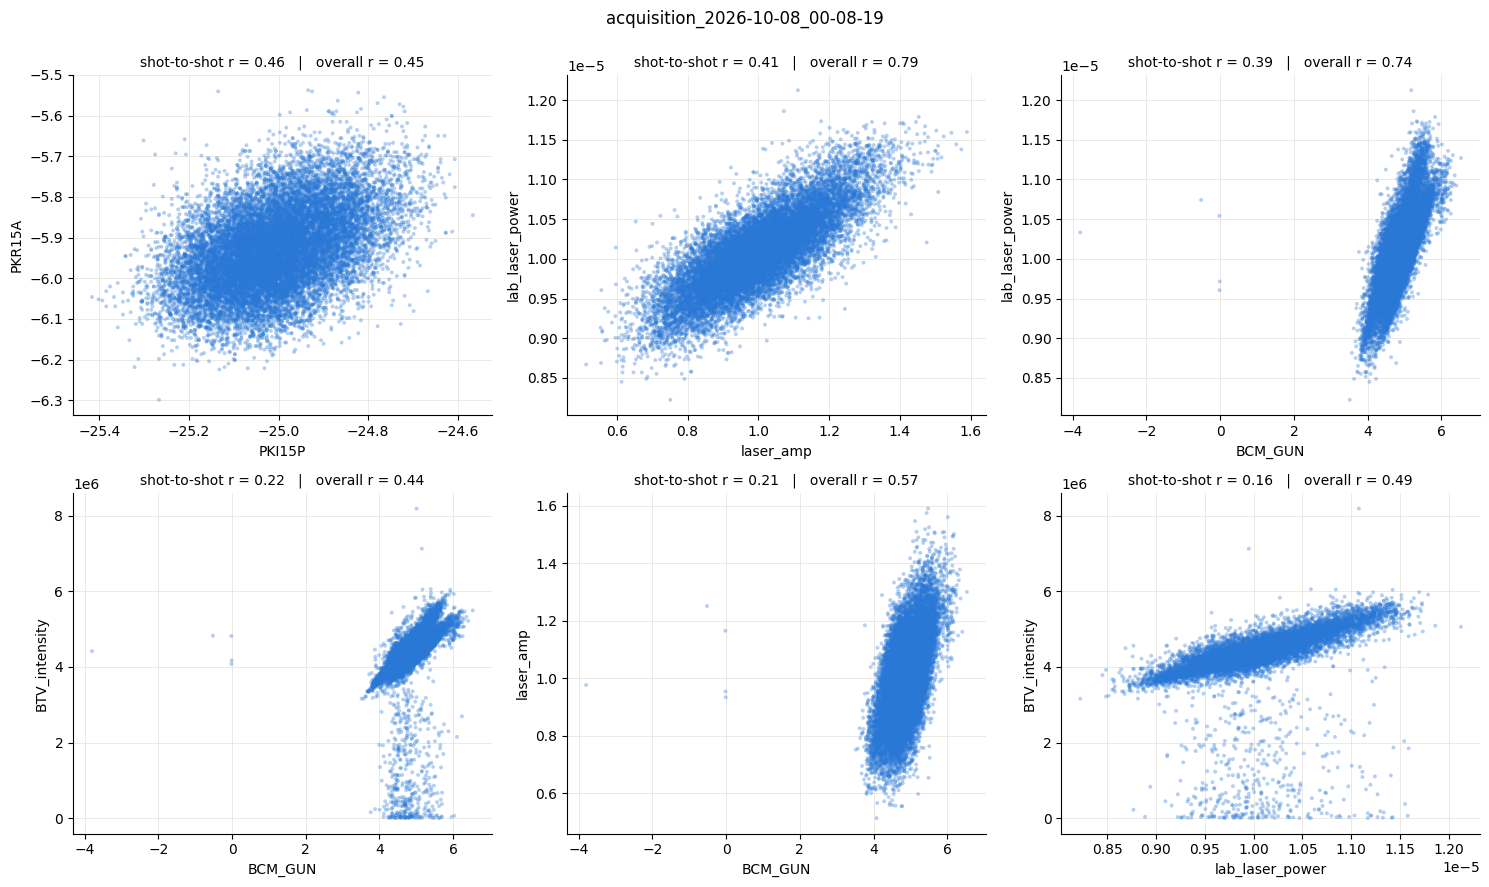

,level_0,level_1,r
20,PKR15A,PKI15P,0.46
2,lab_laser_power,laser_amp,0.41
1,lab_laser_power,BCM_GUN,0.39
55,BTV_intensity,BCM_GUN,0.22
0,laser_amp,BCM_GUN,0.21
57,BTV_intensity,lab_laser_power,0.16
3,PGLA_drop,BCM_GUN,0.15
5,PGLA_drop,lab_laser_power,0.12
47,BTV_amplitude,lab_laser_power,0.11
45,BTV_amplitude,BCM_GUN,0.09


In [17]:
results[RUNS[1]] = analyse_run(RUNS[1])

## Run 2

acquisition_2026-10-08_15-42-27: 118 chunks, 11800 shots, 3 contiguous segment(s)


/tmp/ipykernel_1489128/2563599605.py:31: RuntimeWarning: invalid value encountered in sqrt
  "sigma_x": np.sqrt(proj_x @ (x_mm - mean_x) ** 2 / total),
/tmp/ipykernel_1489128/2563599605.py:32: RuntimeWarning: invalid value encountered in sqrt
  "sigma_y": np.sqrt(proj_y @ (y_mm - mean_y) ** 2 / total)}


camera: computed 11800 shots, 154 blank images (NaN) -> /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/05_correlations/acquisition_2026-10-08_15-42-27/btv0125_params.csv


,mean,std,min,max
BCM_GUN,1.144563e-01,2.922153e-02,-0.017430,2.155860e-01
laser_amp,1.000000e+00,1.605002e-01,0.460697,1.638975e+00
lab_laser_power,3.650182e-06,7.213852e-08,0.000003,4.116840e-06
PGLA_drop,1.377946e-01,1.065352e+00,-4.882812,3.906250e+00
PKI15A,1.316452e+02,5.422046e-01,130.103975,1.330107e+02
PKI15P,-2.512810e+01,2.592297e-01,-26.088580,-2.457491e+01
PKR15A,-5.965037e+00,2.634419e-01,-6.959444,-5.440028e+00
DHG0130,5.404932e-01,1.345576e-03,0.535662,5.455881e-01
SNH_110,2.200042e+02,7.538390e-03,219.983994,2.200260e+02
SNI_120,3.303216e+02,1.800198e-01,329.477814,3.306986e+02


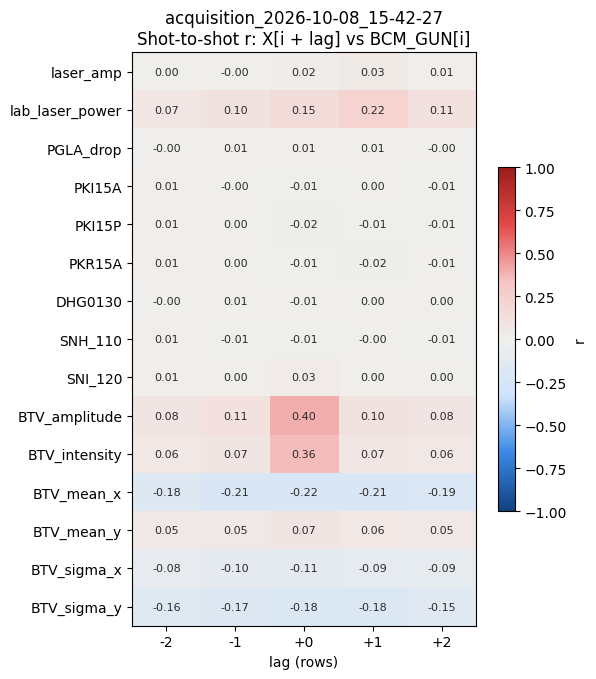

kept 9436 / 11800 shots (dropped 2334 frozen laser, 33 frozen camera, 3 lost to the shift)


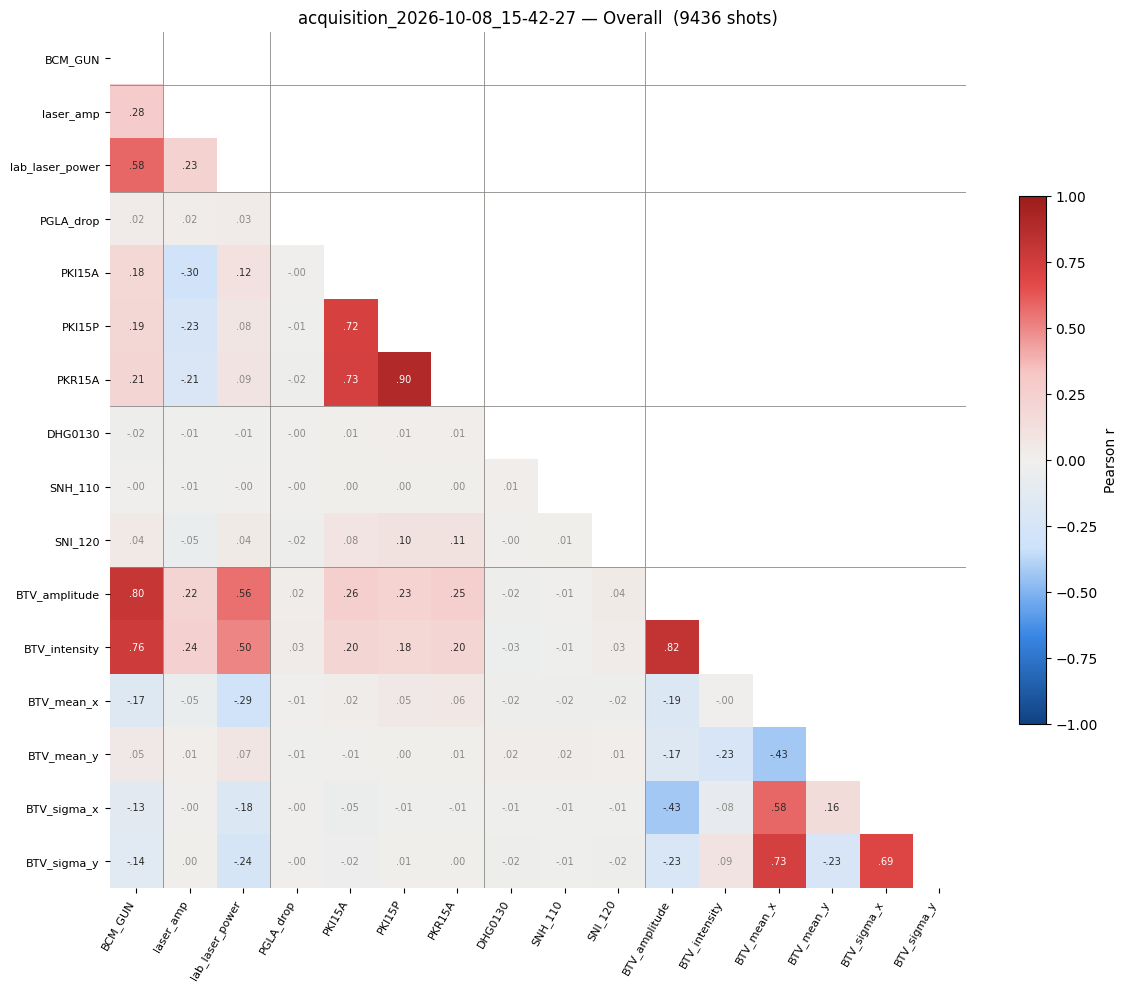

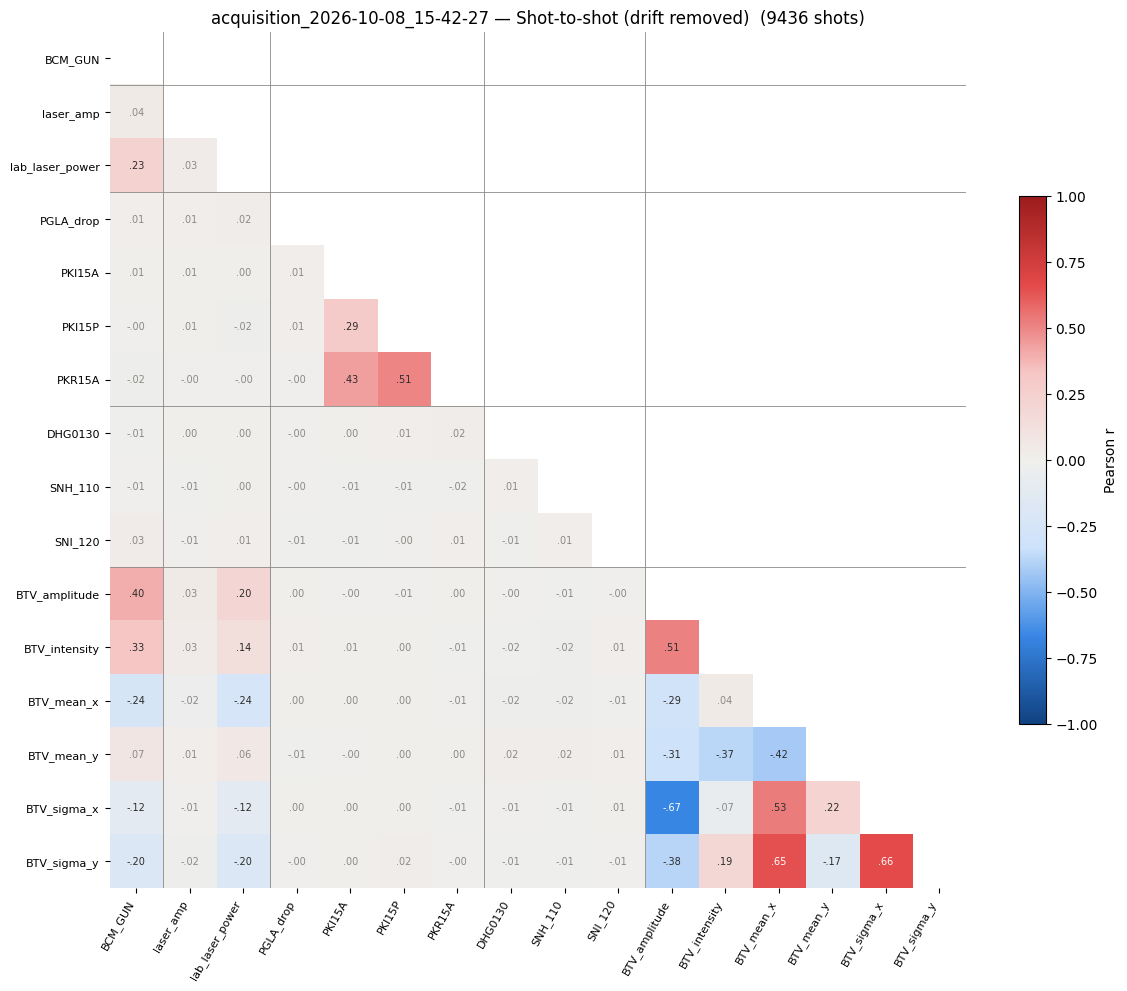

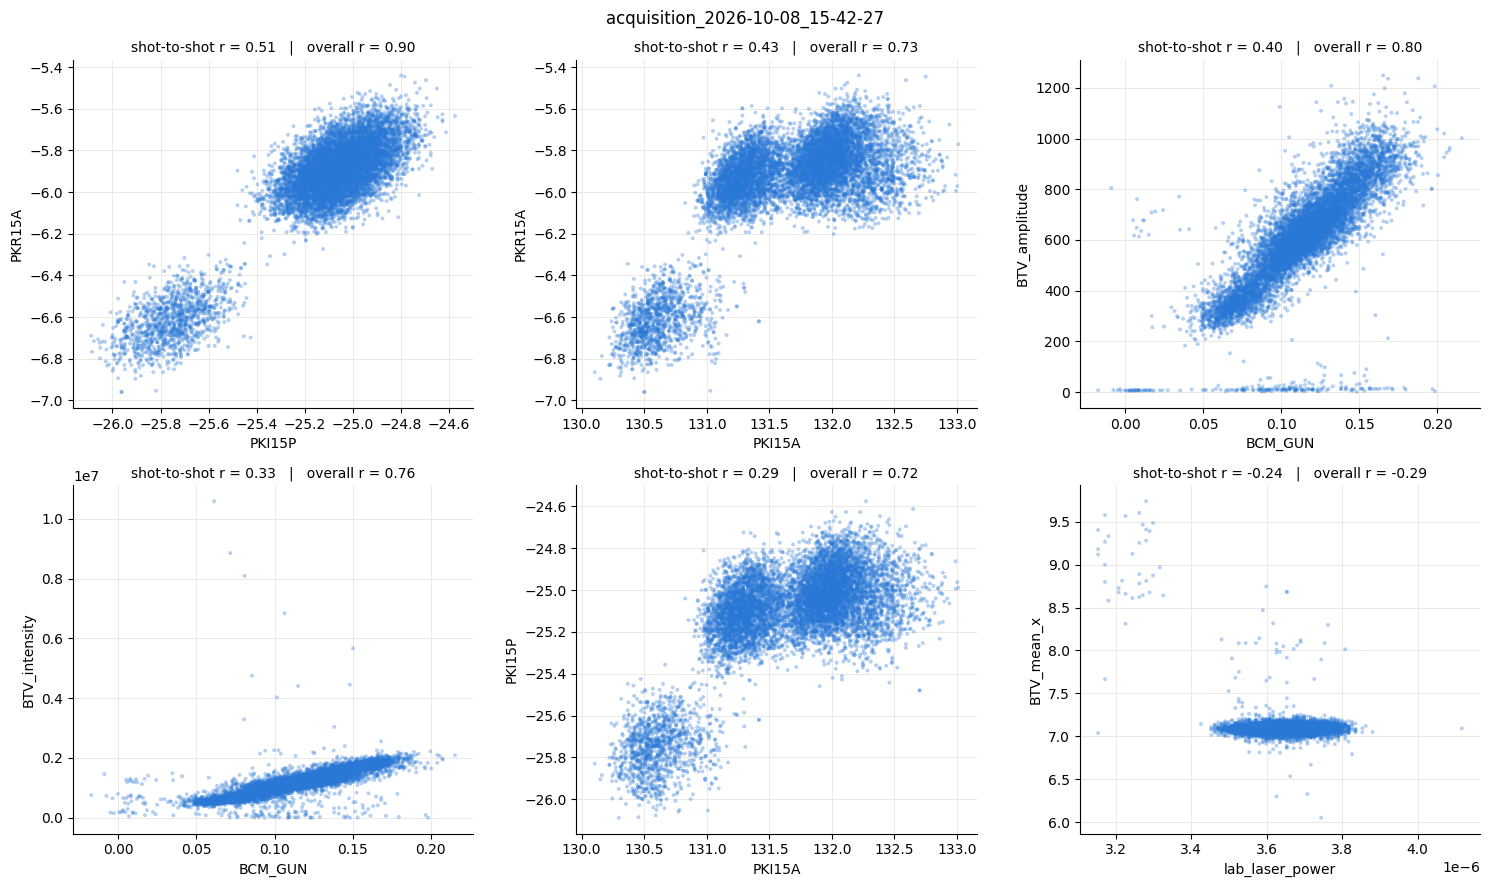

,level_0,level_1,r
20,PKR15A,PKI15P,0.51
19,PKR15A,PKI15A,0.43
45,BTV_amplitude,BCM_GUN,0.40
55,BTV_intensity,BCM_GUN,0.33
14,PKI15P,PKI15A,0.29
68,BTV_mean_x,lab_laser_power,-0.24
66,BTV_mean_x,BCM_GUN,-0.24
1,lab_laser_power,BCM_GUN,0.23
105,BTV_sigma_y,BCM_GUN,-0.20
47,BTV_amplitude,lab_laser_power,0.20


In [18]:
results[RUNS[2]] = analyse_run(RUNS[2])

## Run 3

acquisition_2026-10-08_21-11-47: 200 chunks, 20000 shots, 1 contiguous segment(s)
camera: computed 20000 shots, 31 blank images (NaN) -> /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/05_correlations/acquisition_2026-10-08_21-11-47/btv0125_params.csv


,mean,std,min,max
BCM_GUN,5.460095e+00,4.843507e-01,-0.036089,7.025874e+00
laser_amp,1.000000e+00,1.642930e-01,0.513317,1.673779e+00
lab_laser_power,1.104029e-05,5.277533e-07,0.000009,1.286852e-05
PGLA_drop,6.569092e+00,1.217403e+00,-1.953125,2.441406e+01
PKI15A,1.315172e+02,9.771947e+00,-33.949908,1.330997e+02
PKI15P,-2.508971e+01,1.204123e-01,-25.789867,-2.464384e+01
PKR15A,-5.788949e+00,2.076255e-01,-9.228516,-5.362477e+00
DHG0130,5.404758e-01,1.356853e-03,0.535280,5.452063e-01
SNH_110,2.200038e+02,7.488785e-03,219.983994,2.200260e+02
SNI_120,3.303469e+02,1.699255e-01,329.447296,3.307291e+02


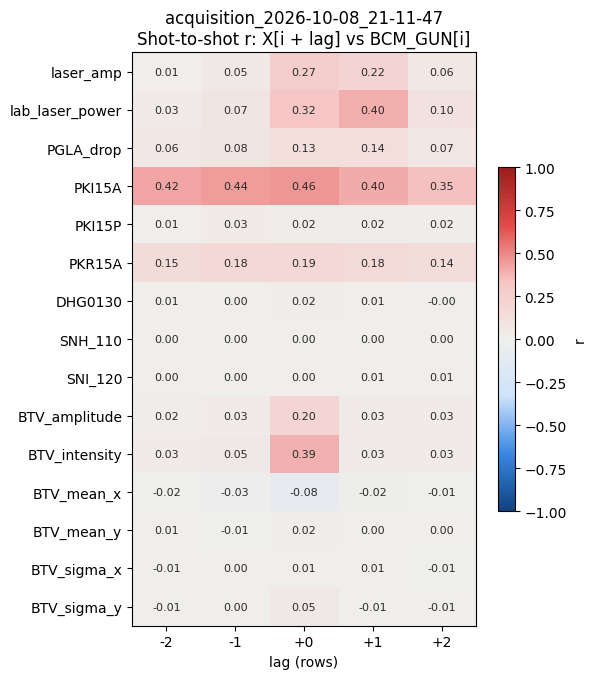

kept 17443 / 20000 shots (dropped 2534 frozen laser, 24 frozen camera, 1 lost to the shift)


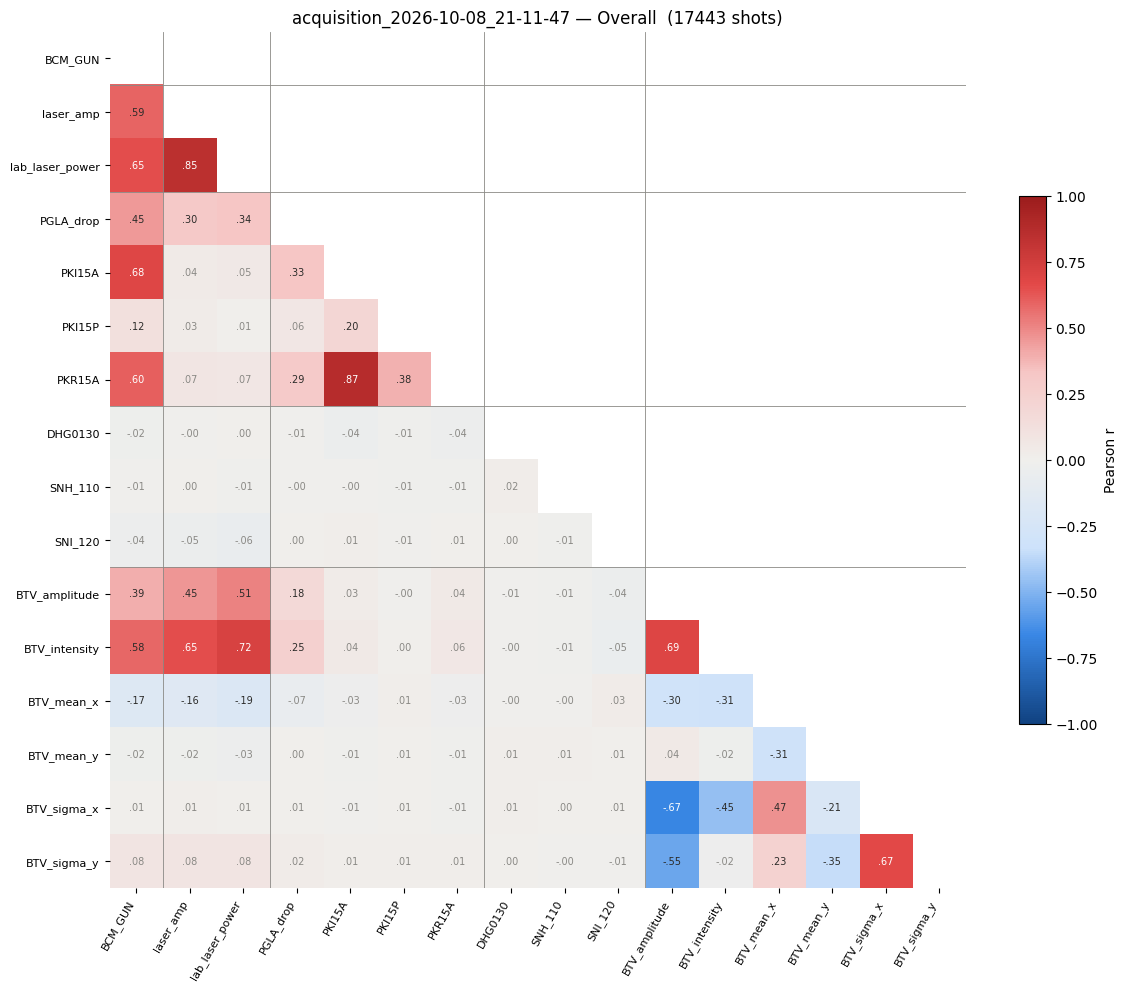

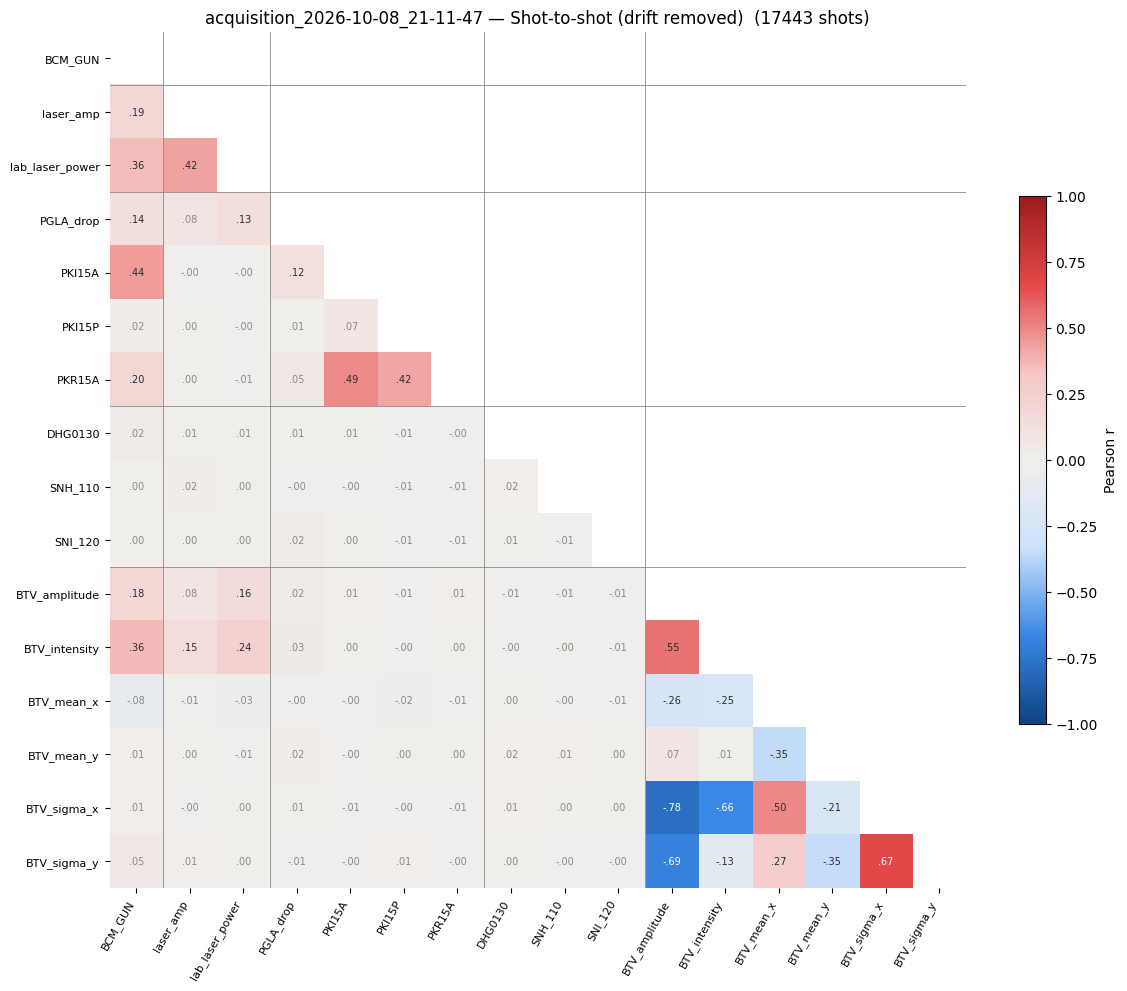

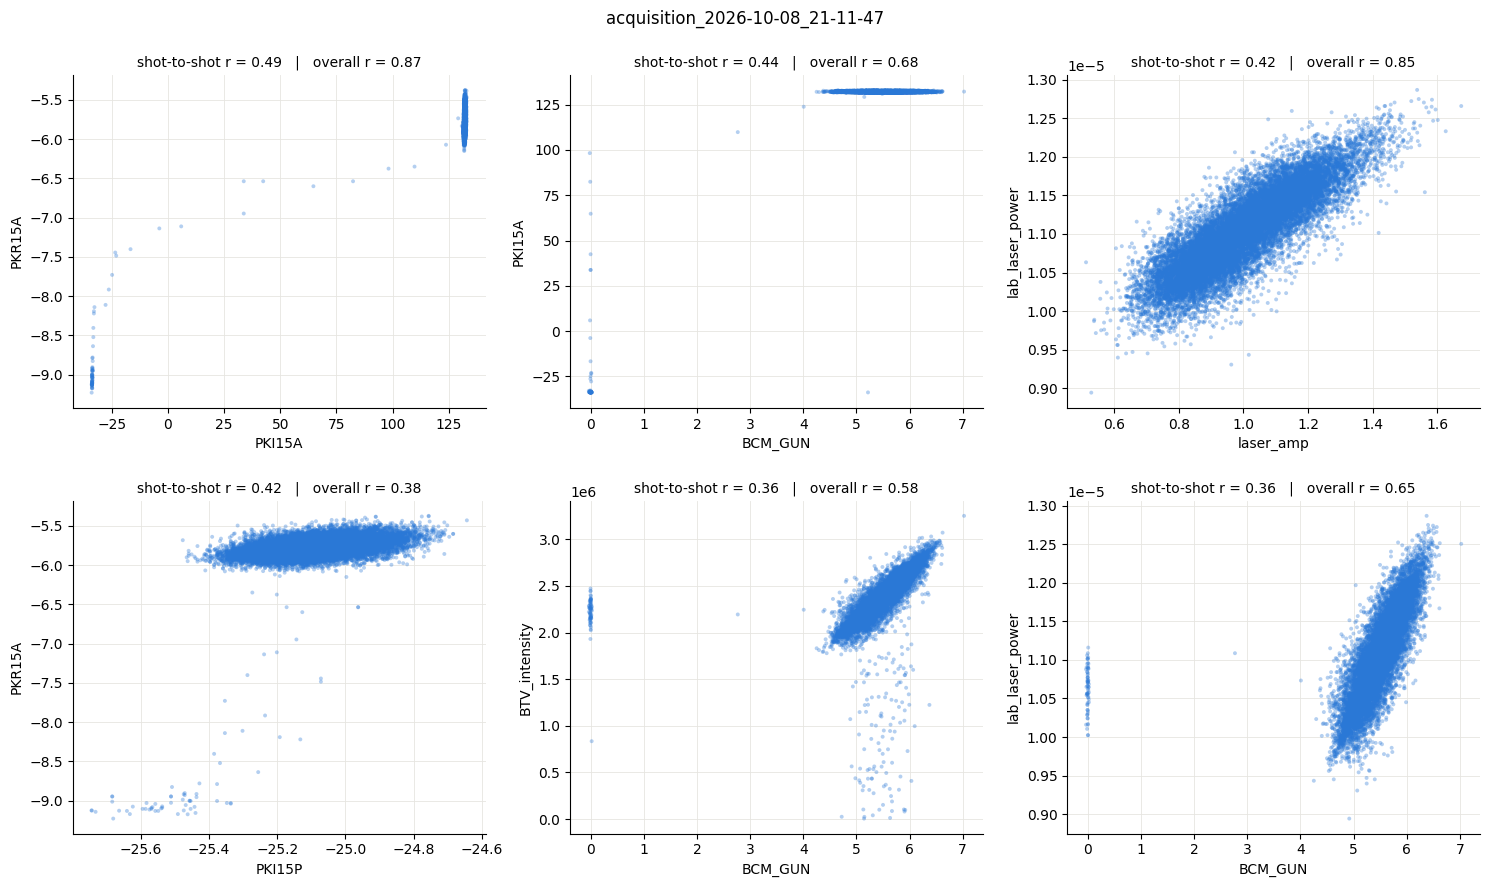

,level_0,level_1,r
19,PKR15A,PKI15A,0.49
6,PKI15A,BCM_GUN,0.44
2,lab_laser_power,laser_amp,0.42
20,PKR15A,PKI15P,0.42
55,BTV_intensity,BCM_GUN,0.36
1,lab_laser_power,BCM_GUN,0.36
57,BTV_intensity,lab_laser_power,0.24
15,PKR15A,BCM_GUN,0.20
0,laser_amp,BCM_GUN,0.19
45,BTV_amplitude,BCM_GUN,0.18


In [19]:
results[RUNS[3]] = analyse_run(RUNS[3])

## Run 4

acquisition_2026-10-09_07-46-07: 61 chunks, 6100 shots, 2 contiguous segment(s)
camera: computed 6100 shots, 2 blank images (NaN) -> /lustre/work/pdl18409/shared/data/optimisation/teams/fast-approximate/Fast-Approximate/results/05_correlations/acquisition_2026-10-09_07-46-07/btv0125_params.csv


,mean,std,min,max
BCM_GUN,7.011114e+00,2.200969e+00,1.122837,1.850966e+01
laser_amp,1.000000e+00,3.176791e-01,0.183098,3.532501e+00
lab_laser_power,1.360331e-05,3.512089e-06,0.000005,3.863286e-05
PGLA_drop,8.429335e+00,2.783320e+00,0.976562,2.148438e+01
PKI15A,1.319553e+02,1.842492e-01,131.278722,1.328441e+02
PKI15P,-2.506520e+01,1.281898e-01,-25.502642,-2.460363e+01
PKR15A,-5.802601e+00,1.013384e-01,-6.166705,-5.417050e+00
DHG0130,5.404805e-01,1.362541e-03,0.535662,5.448245e-01
SNH_110,2.200036e+02,7.584075e-03,219.983994,2.200260e+02
SNI_120,3.303215e+02,1.791450e-01,329.447296,3.306681e+02


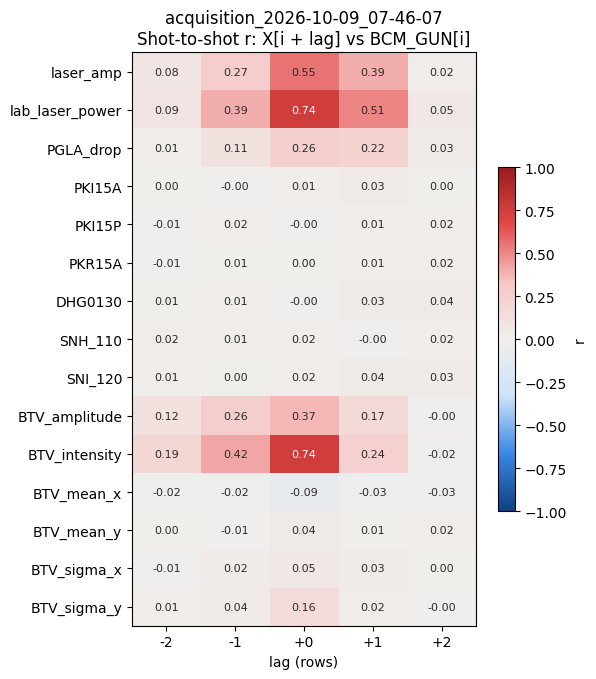

kept 4917 / 6100 shots (dropped 1180 frozen laser, 1 frozen camera, 2 lost to the shift)


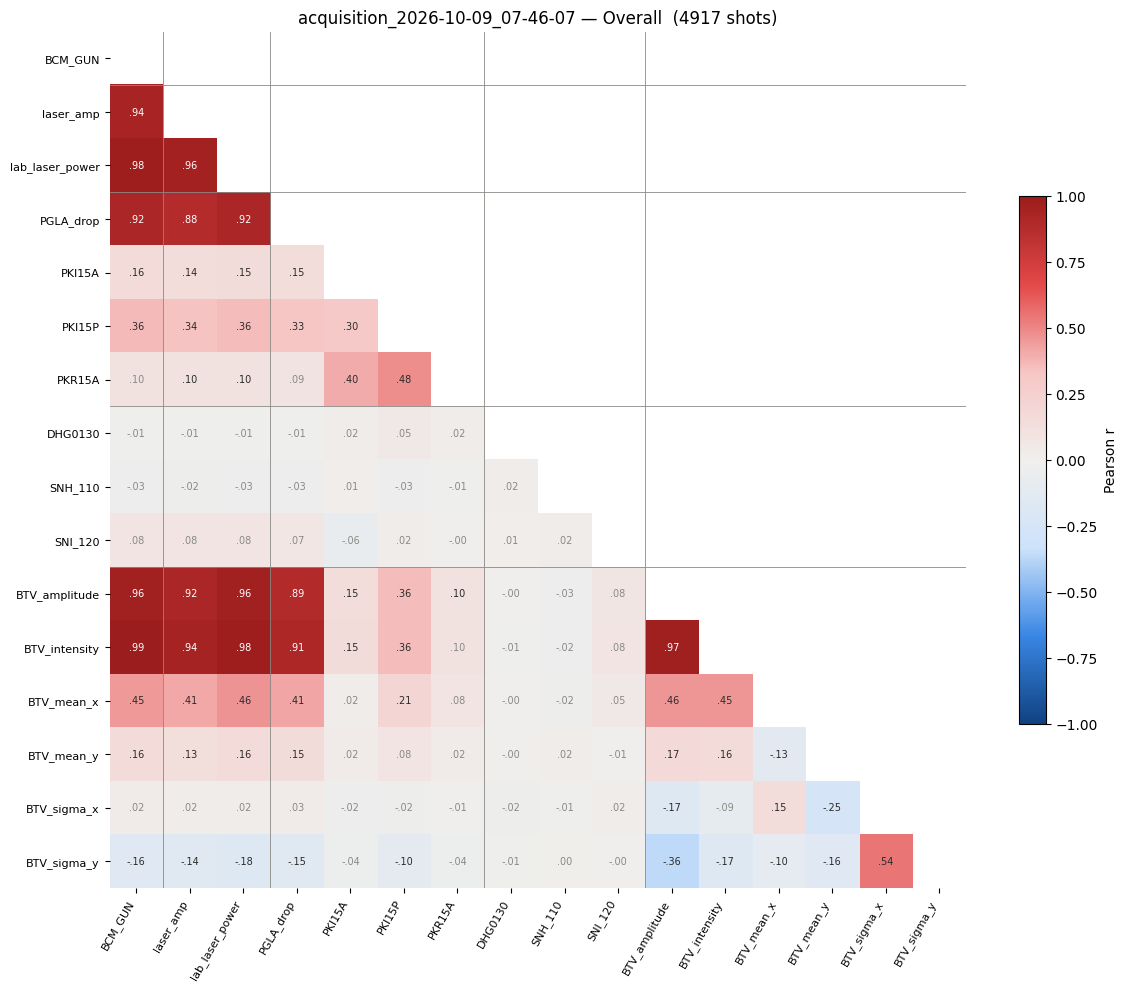

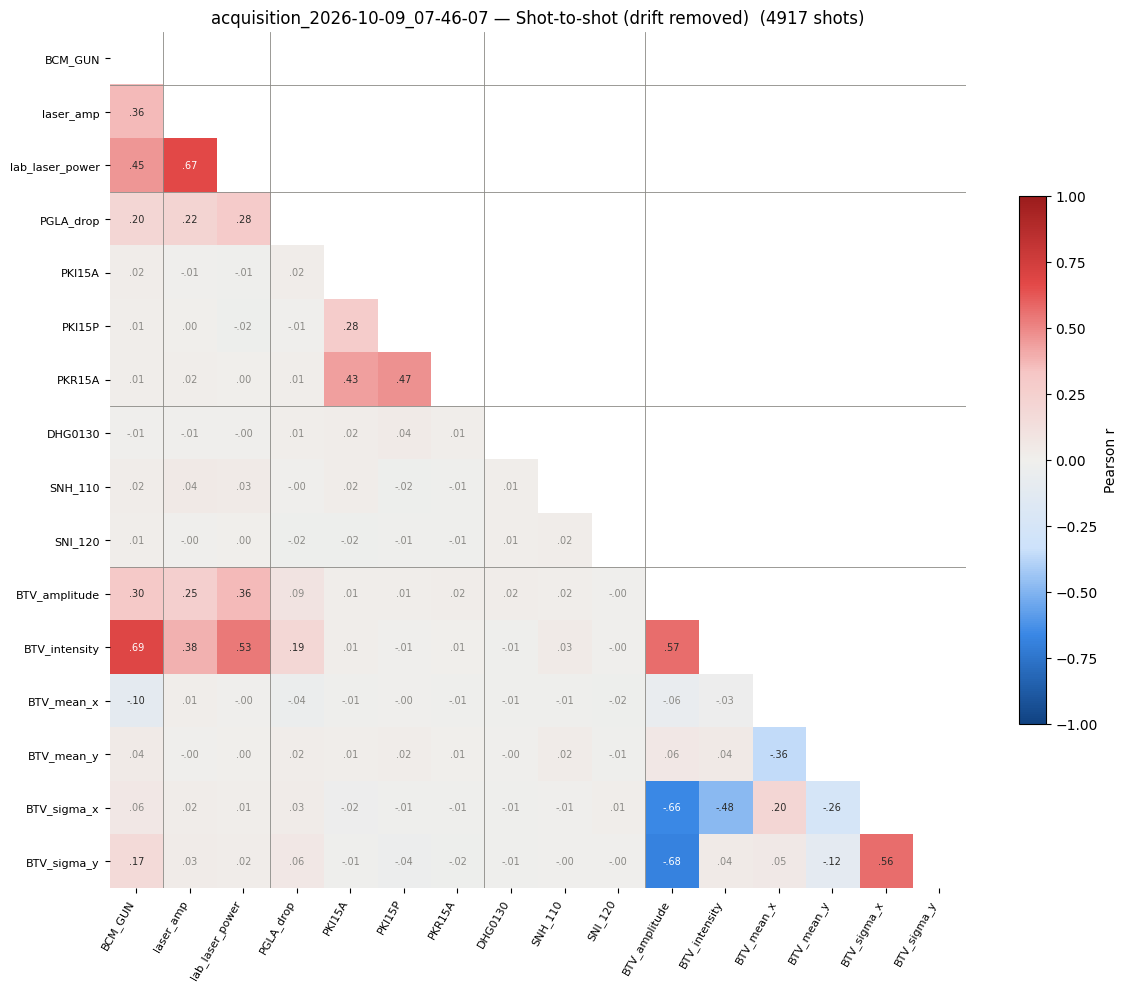

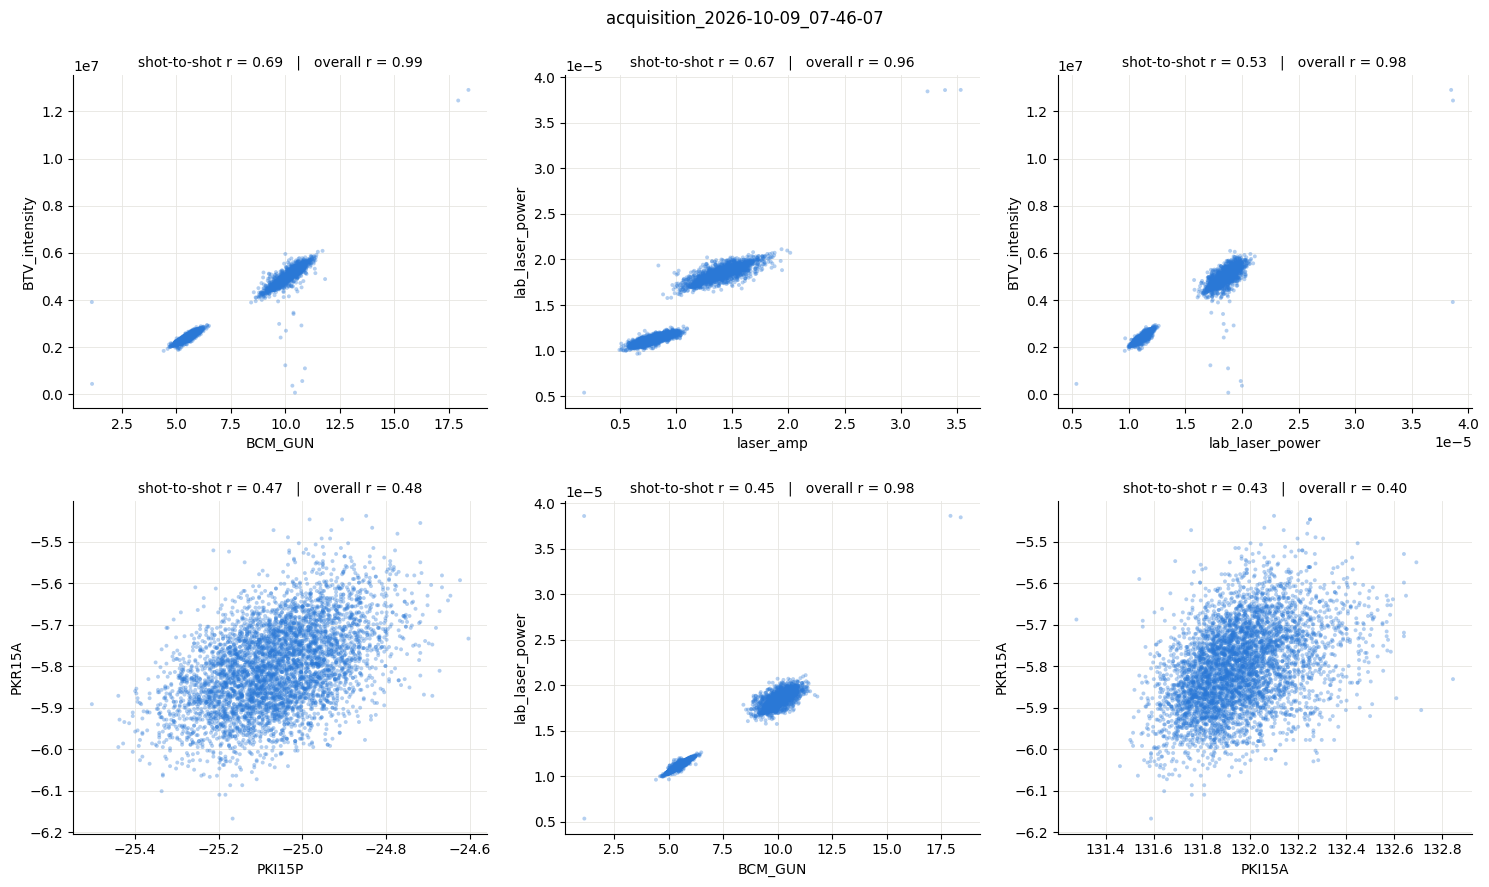

,level_0,level_1,r
55,BTV_intensity,BCM_GUN,0.69
2,lab_laser_power,laser_amp,0.67
57,BTV_intensity,lab_laser_power,0.53
20,PKR15A,PKI15P,0.47
1,lab_laser_power,BCM_GUN,0.45
19,PKR15A,PKI15A,0.43
56,BTV_intensity,laser_amp,0.38
47,BTV_amplitude,lab_laser_power,0.36
0,laser_amp,BCM_GUN,0.36
45,BTV_amplitude,BCM_GUN,0.30


In [20]:
results[RUNS[4]] = analyse_run(RUNS[4])

(20000, 340)


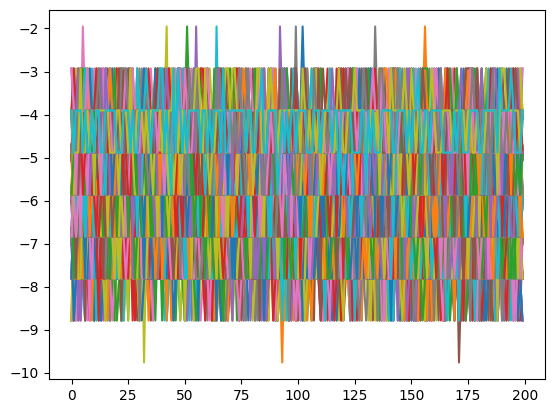

In [25]:
# plot PK* of run 3
def plot_PKs(run):
    files = clean[run]
    #out = OUT_ROOT / run
    #out.mkdir(parents=True, exist_ok=True)
    #chunk, segment = shot_index(files)
    #print(f"{run}: {len(files)} chunks, {len(chunk)} shots, {segment.max() + 1} contiguous segment(s)")

    # raw, laser_frozen, btv_frozen = build_table(run, files)
    # print( "PKR15A shape"
    PKRs_all = load(files, "PKR15A")[:, 0, FLAT_TOP]
    print( PKRs_all.shape )
    plt.plot( PKRs_all[:200] )
    
plot_PKs( RUNS[3] )

## Comparison of the runs

Shot-to-shot r of every quantity with `BCM_GUN`, one column per run; and the lag with the largest |r| per run,
to check the +1 shift of group B.

In [ ]:
vs_bcm = pd.DataFrame({run: res["matrices"]["Shot-to-shot (drift removed)"]["BCM_GUN"].drop("BCM_GUN")
                       for run, res in results.items()})
best_lag = pd.DataFrame({run: res["lag_table"].abs().idxmax(axis=1) for run, res in results.items()})
shots = pd.DataFrame({run: [res["n_shots"], res["n_kept"]] for run, res in results.items()}, index=["shots", "kept"])

display(shots)
display(vs_bcm.round(2))
display(best_lag)

fig, ax = plt.subplots(figsize=(1.2 * len(vs_bcm.columns) + 4, 0.36 * len(vs_bcm) + 2))
im = ax.imshow(vs_bcm, cmap=DIVERGING, vmin=-1, vmax=1, aspect="auto")
for (i, j), r in np.ndenumerate(vs_bcm.to_numpy()):
    ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(r) > 0.6 else INK)
ax.set_xticks(range(vs_bcm.shape[1]), [r.removeprefix("acquisition_") for r in vs_bcm.columns], rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(vs_bcm)), vs_bcm.index, fontsize=8)
ax.set_title("Shot-to-shot r with BCM_GUN, per run")
fig.colorbar(im, ax=ax, shrink=0.6, label="r")
fig.tight_layout()
save(fig, OUT_ROOT / "runs_vs_bcm.png")
plt.show()

vs_bcm.to_csv(OUT_ROOT / "runs_vs_bcm.csv")
best_lag.to_csv(OUT_ROOT / "runs_best_lag.csv")